# Exact Gutzwiller-projected Berry phases: even Majorana-Chern regions

This notebook runs both cell-product Gutzwiller projections on a **4 × 4 unit-cell lattice** by exact enumeration. Odd Majorana-Chern-number points are skipped; gapless and numerically unreliable points are masked in the figure.

Keep this notebook in `gutzwiller_projection_figure/`, together with the supplied Python modules. You can also launch Jupyter from its parent directory. Edit the parameter cell, then choose **Kernel → Restart & Run All**.

The default full scan uses exact sums over up to $2^{16}$ Fock configurations per projected link and can take several minutes. Repeating an unchanged run resumes from its checkpoint. Changing parameters creates a separate checkpoint automatically.

In [1]:
from pathlib import Path
import json
import os
import subprocess
import sys

import pandas as pd
from IPython.display import Image, display

# Works when Jupyter is launched inside the code folder or its parent.
candidates = [Path.cwd(), Path.cwd() / 'gutzwiller_projection_figure']
PROJECT_DIR = next(
    (path.resolve() for path in candidates
     if (path / 'scan_even_chern_phase_diagram.py').is_file()),
    None,
)
if PROJECT_DIR is None:
    raise FileNotFoundError(
        'Open Jupyter in gutzwiller_projection_figure/ or its parent directory.'
    )
SCRIPT_PATH = PROJECT_DIR / 'scan_even_chern_phase_diagram.py'
print(f'Code folder: {PROJECT_DIR}')

Code folder: /Users/xuzheying/Library/CloudStorage/OneDrive-HKUST/Work Documents/AI Projects/Many body Berry phase/gutzwiller_projection_figure


## 1. Tunable parameters

`delta_values` specifies $\Delta$, with $\Delta_p=\Delta$ and $\Delta_s=\Delta/2$. Set `m_values` to a list such as `[-3.0, -2.0, -1.0]` to override the evenly spaced mass grid. Full projection corresponds to `projection_strength = 1.0`. Increase `steps_per_leg` for a finer twist loop.

In [2]:
# Mass grid; explicit m_values overrides m_min/m_max/m_points when not None.
m_values = None
m_min = -4.75
m_max = 4.75
m_points = 20

# Pairing and Hamiltonian parameters.
delta_values = [0.25, 0.75, 1.0, 1.5]
t = 1.0
t1 = 1.0

# Gutzwiller projection and numerical controls.
projection_strength = 1.0       # 0 <= g <= 1; 1 is full projection
steps_per_leg = 2               # Wilson-loop resolution
pairing_twist = 'cosine'        # 'cosine' or 'linear'
chern_grid = 40                 # Fukui mesh for Majorana-Chern classification
minimum_chern_gap = 1e-5
minimum_reliable_link = 1e-8
workers = min(4, os.cpu_count() or 1)

## 2. Run the exact scan

Progress is printed below. Interrupting this cell terminates the scan process; already completed grid points remain checkpointed.

In [3]:
command = [
    sys.executable, str(SCRIPT_PATH),
    '--delta-values', ','.join(str(value) for value in delta_values),
    '--t', str(t),
    '--t1', str(t1),
    '--projection-strength', str(projection_strength),
    '--steps-per-leg', str(steps_per_leg),
    '--pairing-twist', pairing_twist,
    '--chern-grid', str(chern_grid),
    '--minimum-chern-gap', str(minimum_chern_gap),
    '--minimum-reliable-link', str(minimum_reliable_link),
    '--workers', str(workers),
]
if m_values is not None:
    command += ['--m-values', ','.join(str(value) for value in m_values)]
else:
    command += [
        '--m-min', str(m_min),
        '--m-max', str(m_max),
        '--m-points', str(m_points),
    ]

process = subprocess.Popen(
    command,
    cwd=PROJECT_DIR,
    stdout=subprocess.PIPE,
    stderr=subprocess.STDOUT,
    text=True,
)
output_lines = []
try:
    for line in process.stdout:
        print(line, end='')
        output_lines.append(line)
    return_code = process.wait()
except KeyboardInterrupt:
    process.terminate()
    process.wait()
    raise

if return_code != 0:
    raise RuntimeError(f'Phase-diagram scan failed with exit code {return_code}.')

json_lines = [line for line in output_lines if line.startswith('JSON: ')]
if not json_lines:
    raise RuntimeError('The scan finished without reporting its JSON output path.')
JSON_PATH = Path(json_lines[-1].split('JSON: ', 1)[1].strip())
CSV_PATH = JSON_PATH.with_suffix('.csv')
FIGURE_PATH = JSON_PATH.with_suffix('.png')

Fock-space validation passed (maximum error 6.241e-14)
Resumed 80 grid points from /Users/xuzheying/Library/CloudStorage/OneDrive-HKUST/Work Documents/AI Projects/Many body Berry phase/gutzwiller_projection_figure/even_chern_phase_diagram_23bf52459fe1.jsonl


Status counts: {'computed': 62, 'odd_nu_M': 12, 'gapless_or_unclassified': 6}
JSON: /Users/xuzheying/Library/CloudStorage/OneDrive-HKUST/Work Documents/AI Projects/Many body Berry phase/gutzwiller_projection_figure/even_chern_phase_diagram_23bf52459fe1.json
CSV: /Users/xuzheying/Library/CloudStorage/OneDrive-HKUST/Work Documents/AI Projects/Many body Berry phase/gutzwiller_projection_figure/even_chern_phase_diagram_23bf52459fe1.csv
Figure: /Users/xuzheying/Library/CloudStorage/OneDrive-HKUST/Work Documents/AI Projects/Many body Berry phase/gutzwiller_projection_figure/even_chern_phase_diagram_23bf52459fe1.png


## 3. Figure and numerical results

Phases in the table are $\theta_{\mathrm{BP}}/\pi$ modulo $\pi$. Points with `reliable_for_plot = False` remain in the CSV/JSON output but are grey in the figure.

Status counts: {'computed': 62, 'odd_nu_M': 12, 'gapless_or_unclassified': 6}
Computed even-nu_M points: 62
Reliable plotted points: 56
JSON: /Users/xuzheying/Library/CloudStorage/OneDrive-HKUST/Work Documents/AI Projects/Many body Berry phase/gutzwiller_projection_figure/even_chern_phase_diagram_23bf52459fe1.json
CSV:  /Users/xuzheying/Library/CloudStorage/OneDrive-HKUST/Work Documents/AI Projects/Many body Berry phase/gutzwiller_projection_figure/even_chern_phase_diagram_23bf52459fe1.csv


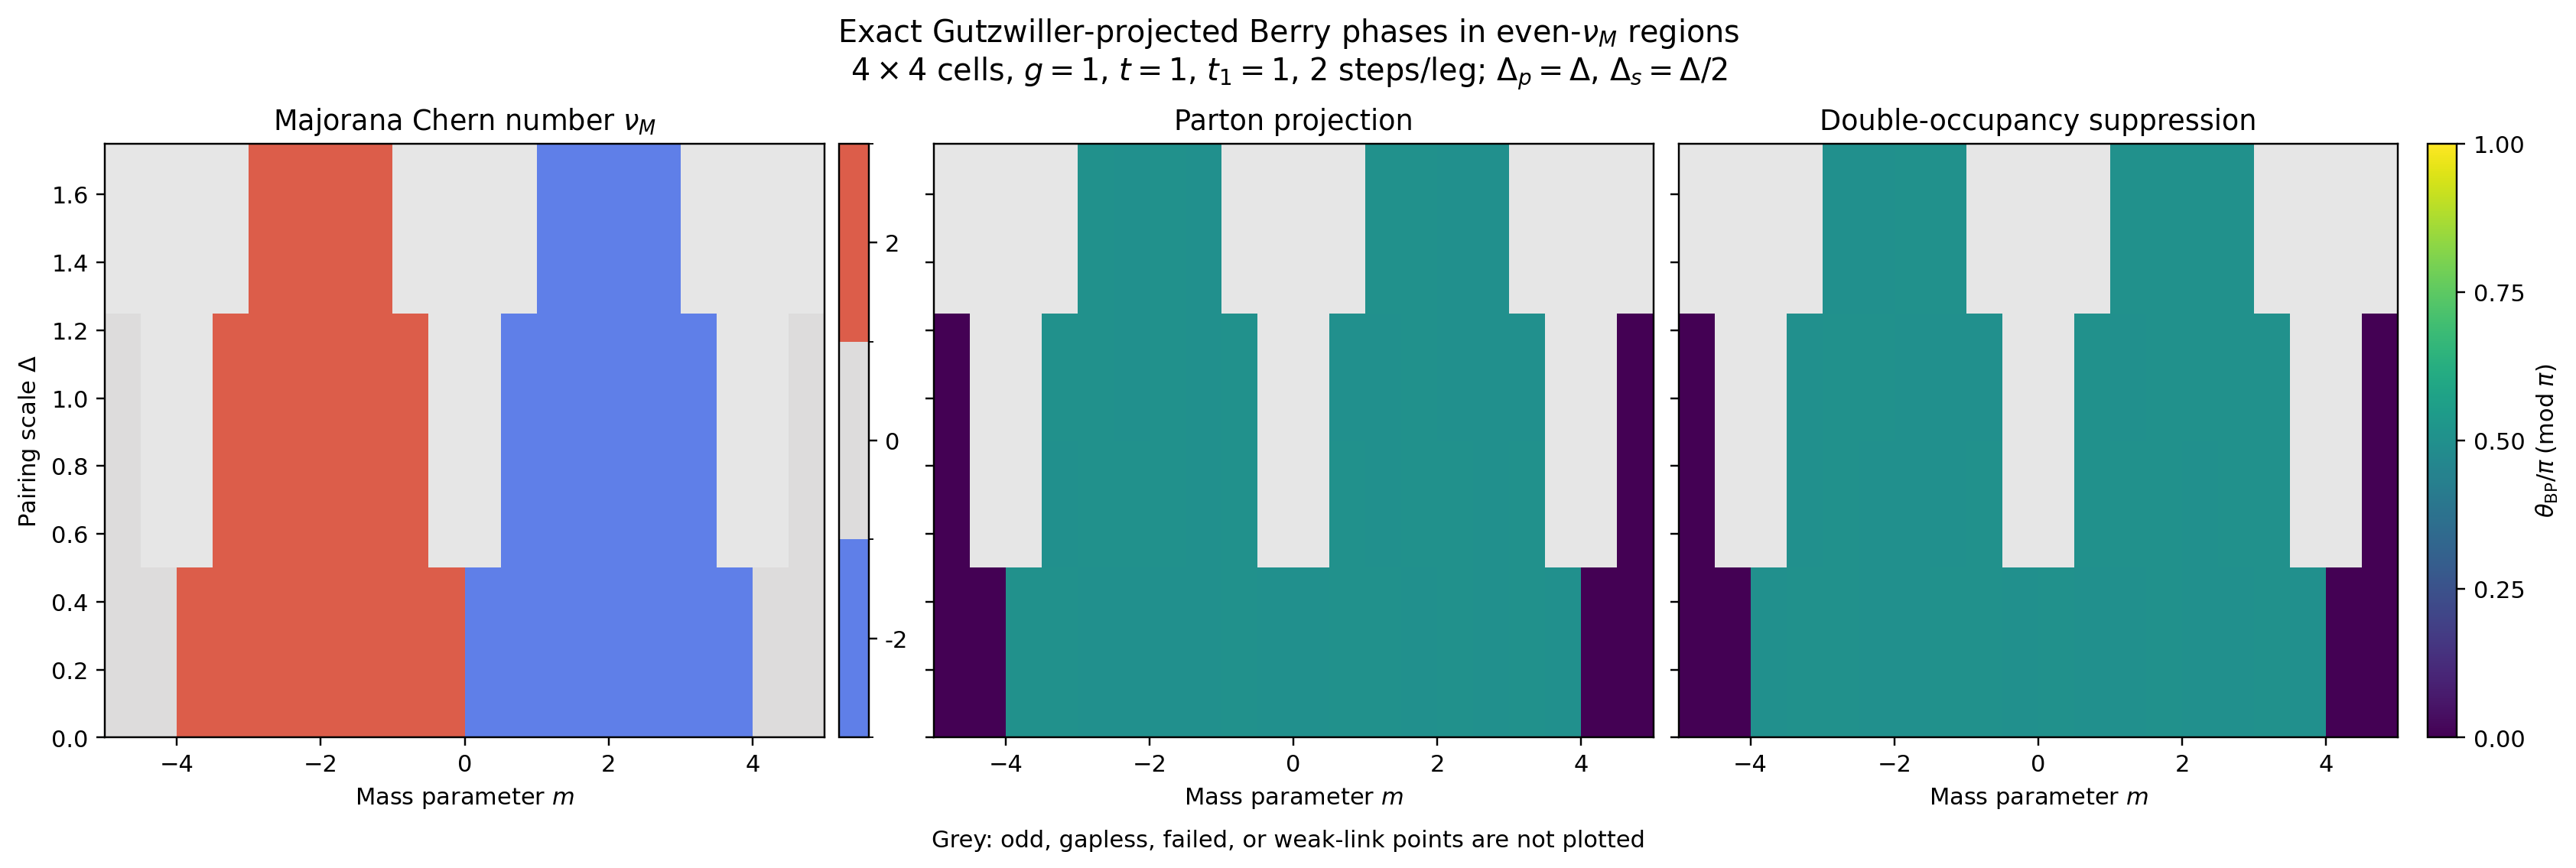

,m,delta,nu_M,reliable_for_plot,parton_berry_phase_mod_pi_over_pi,double_occupancy_berry_phase_mod_pi_over_pi,parton_minimum_link_magnitude,double_occupancy_minimum_link_magnitude
0,-4.75,0.25,0,True,0.000000,0.00000,0.999119,0.998076
1,-4.25,0.25,0,True,0.000000,0.00000,0.995965,0.994293
2,-3.75,0.25,2,True,0.500000,0.50000,0.196250,0.197545
3,-3.25,0.25,2,True,0.500000,0.50000,0.370854,0.372400
4,-2.75,0.25,2,True,0.500000,0.50000,0.531929,0.532184
...,...,...,...,...,...,...,...,...
57,0.25,1.50,0,False,0.811933,0.36166,0.000000,0.000000
58,1.25,1.50,-2,True,0.500000,0.50000,0.529189,0.343217
59,1.75,1.50,-2,True,0.500000,0.50000,0.563298,0.411019
60,2.25,1.50,-2,True,0.500000,0.50000,0.559023,0.367134


In [4]:
results = json.loads(JSON_PATH.read_text(encoding='utf-8'))
table = pd.read_csv(CSV_PATH)

print('Status counts:', results['status_counts'])
print('Computed even-nu_M points:', results['computed_even_points'])
print('Reliable plotted points:', results['reliable_computed_even_points'])
print(f'JSON: {JSON_PATH}')
print(f'CSV:  {CSV_PATH}')
display(Image(filename=str(FIGURE_PATH)))

columns = [
    'm', 'delta', 'nu_M', 'reliable_for_plot',
    'parton_berry_phase_mod_pi_over_pi',
    'double_occupancy_berry_phase_mod_pi_over_pi',
    'parton_minimum_link_magnitude',
    'double_occupancy_minimum_link_magnitude',
]
display(table[columns].round(10).reset_index(drop=True))